<a href="https://colab.research.google.com/github/whitneymbakop/CRM-coursework-1/blob/main/CRM_TASK_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2.1 Feature preparation

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

pandas: 2.2.3
scikit-learn: 1.6.1


In [14]:
features = pd.read_csv('feature_table.csv', index_col=0)
print('Shares:', len(features))
features.head()

Shares: 486


,Security,Sector,Mean_weekly_return,Beta,Weeks,Recency,Frequency,Monetary
A,Agilent Technologies,Health Care,0.001121,1.074723,207.0,11.0,2.0,1.400180e+10
AAPL,Apple Inc.,Information Technology,0.003930,1.174835,207.0,11.0,2.0,6.233034e+11
ABBV,AbbVie,Health Care,0.003749,0.425366,207.0,11.0,3.0,6.837054e+10
ABNB,Airbnb,Consumer Discretionary,0.001475,1.472709,207.0,11.0,3.0,3.652850e+10
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207.0,11.0,1.0,3.523027e+10


In [15]:
risk_return = features[['Mean_weekly_return', 'Beta']]

activity = features[['Recency', 'Frequency', 'Monetary']]

print('Shares in risk/return matrix:', len(risk_return))
print('Shares in activity matrix:', len(activity))
print('Same shares in both (common set):', risk_return.index.equals(activity.index))

Shares in risk/return matrix: 486
Shares in activity matrix: 486
Same shares in both (common set): True


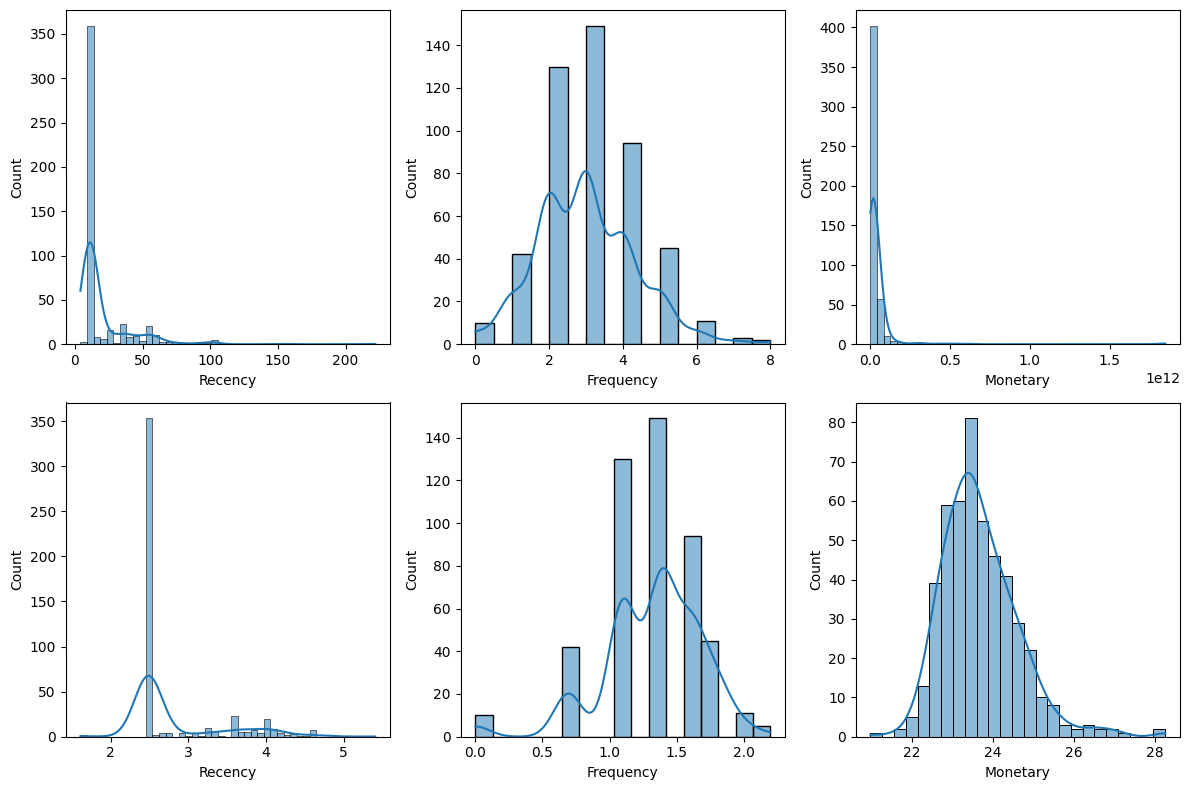

Skew before:
Mean_weekly_return     0.87
Beta                   1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: float64

Skew after log1p:
Recency      1.58
Frequency   -0.93
Monetary     1.08
dtype: float64


In [16]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1); sns.histplot(activity['Recency'], kde=True)
plt.subplot(2, 3, 2); sns.histplot(activity['Frequency'], kde=True)
plt.subplot(2, 3, 3); sns.histplot(activity['Monetary'], kde=True)
plt.subplot(2, 3, 4); sns.histplot(np.log1p(activity['Recency']), kde=True)
plt.subplot(2, 3, 5); sns.histplot(np.log1p(activity['Frequency']), kde=True)
plt.subplot(2, 3, 6); sns.histplot(np.log1p(activity['Monetary']), kde=True)
plt.tight_layout()
plt.savefig('rfm_before_after_log1p.png', dpi=150)
plt.show()

print('Skew before:'); print(features[['Mean_weekly_return', 'Beta', 'Recency', 'Frequency', 'Monetary']].skew().round(2))
print('\nSkew after log1p:'); print(np.log1p(activity).skew().round(2))

In [17]:
cols = ['Mean_weekly_return', 'Beta', 'Recency', 'Frequency', 'Monetary']
z = pd.DataFrame(StandardScaler().fit_transform(features[cols]), columns=cols, index=features.index)
print('Outliers per feature (|z| > 3):')
print((z.abs() > 3).sum())

print('\nHighest beta:')
print(features.sort_values('Beta', ascending=False)[['Security', 'Beta']].head(3))

Outliers per feature (|z| > 3):
Mean_weekly_return     6
Beta                   2
Recency               11
Frequency              5
Monetary               5
dtype: int64

Highest beta:
            Security      Beta
CVNA         Carvana  3.778560
XYZ      Block, Inc.  2.504520
COHR  Coherent Corp.  2.139305


In [18]:
activity_log = pd.DataFrame(index=activity.index)
activity_log['Recency'] = np.log1p(activity['Recency'])
activity_log['Frequency'] = activity['Frequency']
activity_log['Monetary'] = np.log1p(activity['Monetary'])

print(activity_log.skew().round(2))

Recency      1.58
Frequency    0.42
Monetary     1.08
dtype: float64


In [19]:
scaler_rr = StandardScaler()
scaler_rr.fit(risk_return)
X_rr = scaler_rr.transform(risk_return)

scaler_rfm = StandardScaler()
scaler_rfm.fit(activity_log)
X_rfm = scaler_rfm.transform(activity_log)

print('Risk/return  mean:', X_rr.mean(axis=0).round(2), '| std:', X_rr.std(axis=0).round(2))
print('Activity     mean:', X_rfm.mean(axis=0).round(2), '| std:', X_rfm.std(axis=0).round(2))

Risk/return  mean: [0. 0.] | std: [1. 1.]
Activity     mean: [-0. -0. -0.] | std: [1. 1. 1.]


2.2 Agglomerative clustering

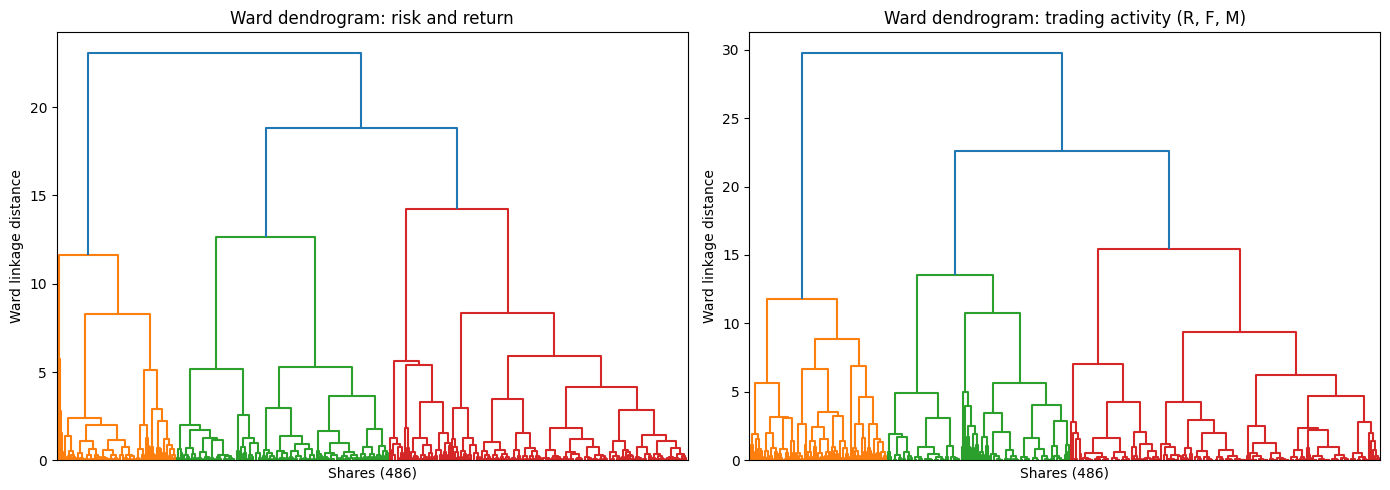

In [20]:
Z_rr = linkage(X_rr, method='ward', metric='euclidean')
Z_rfm = linkage(X_rfm, method='ward', metric='euclidean')

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
dendrogram(Z_rr, no_labels=True)
plt.title('Ward dendrogram: risk and return')
plt.xlabel('Shares (486)')
plt.ylabel('Ward linkage distance')

plt.subplot(1, 2, 2)
dendrogram(Z_rfm, no_labels=True)
plt.title('Ward dendrogram: trading activity (R, F, M)')
plt.xlabel('Shares (486)')
plt.ylabel('Ward linkage distance')

plt.tight_layout()
plt.savefig('ward_dendrograms.png', dpi=150)
plt.show()

In [21]:
ward_rr_results = []
ward_rfm_results = []

for k in range(2, 9):
    labels = cut_tree(Z_rr, n_clusters=k).ravel() + 1
    sizes = pd.Series(labels).value_counts().sort_index()
    ward_rr_results.append({'k': k,
                            'Silhouette': round(silhouette_score(X_rr, labels), 3),
                            'Smallest': sizes.min(), 'Largest': sizes.max(),
                            'Sizes': sizes.tolist()})

    labels = cut_tree(Z_rfm, n_clusters=k).ravel() + 1
    sizes = pd.Series(labels).value_counts().sort_index()
    ward_rfm_results.append({'k': k,
                             'Silhouette': round(silhouette_score(X_rfm, labels), 3),
                             'Smallest': sizes.min(), 'Largest': sizes.max(),
                             'Sizes': sizes.tolist()})

ward_rr_results = pd.DataFrame(ward_rr_results).set_index('k')
ward_rfm_results = pd.DataFrame(ward_rfm_results).set_index('k')

print('Ward – risk and return'); print(ward_rr_results)
print('\nWard – trading activity'); print(ward_rfm_results)

Ward – risk and return
   Silhouette  Smallest  Largest                             Sizes
k                                                                 
2       0.339        92      394                         [394, 92]
3       0.274        92      230                    [230, 92, 164]
4       0.282        48      182                [182, 92, 164, 48]
5       0.304        48      182             [182, 92, 98, 48, 66]
6       0.320         5      182          [182, 87, 98, 48, 66, 5]
7       0.324         5      160      [160, 87, 98, 48, 66, 22, 5]
8       0.321         5      160  [160, 56, 98, 48, 66, 22, 31, 5]

Ward – trading activity
   Silhouette  Smallest  Largest                              Sizes
k                                                                  
2       0.402       106      380                         [380, 106]
3       0.335       106      239                    [239, 141, 106]
4       0.293        70      169                [169, 141, 70, 106]
5       0

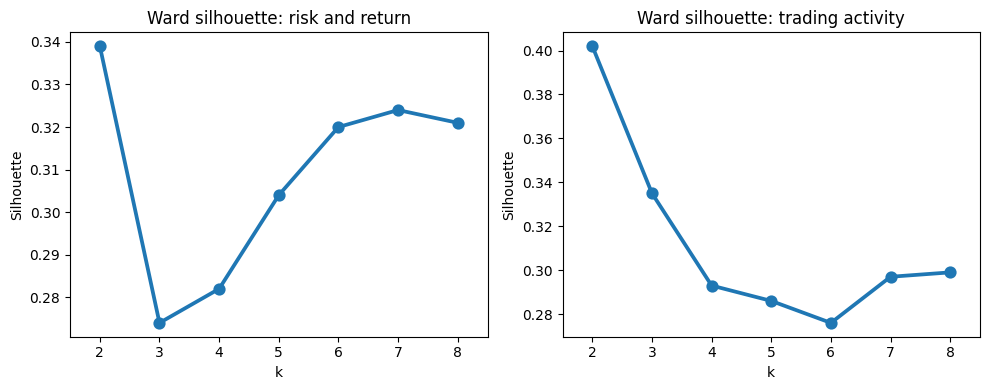

In [22]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.pointplot(x=ward_rr_results.index, y=ward_rr_results['Silhouette'])
plt.title('Ward silhouette: risk and return'); plt.xlabel('k')
plt.subplot(1, 2, 2)
sns.pointplot(x=ward_rfm_results.index, y=ward_rfm_results['Silhouette'])
plt.title('Ward silhouette: trading activity'); plt.xlabel('k')
plt.tight_layout()
plt.savefig('ward_silhouette.png', dpi=150)
plt.show()

In [23]:
for k in range(2, 9):
    labels = cut_tree(Z_rr, n_clusters=k).ravel() + 1
    profile = risk_return.groupby(labels).mean()
    profile['Mean_weekly_return'] = profile['Mean_weekly_return'] * 100
    profile['Count'] = pd.Series(labels).value_counts().sort_index().values
    print('\nRisk/return, k =', k)
    print(profile.round(3))

for k in range(2, 9):
    labels = cut_tree(Z_rfm, n_clusters=k).ravel() + 1
    profile = activity.groupby(labels).median()
    profile['Monetary'] = profile['Monetary'] / 1e9
    profile['Count'] = pd.Series(labels).value_counts().sort_index().values
    print('\nTrading activity, k =', k)
    print(profile.round(1))


Risk/return, k = 2
   Mean_weekly_return   Beta  Count
1               0.205  0.898    394
2               0.632  1.298     92

Risk/return, k = 3
   Mean_weekly_return   Beta  Count
1               0.146  1.110    230
2               0.632  1.298     92
3               0.287  0.601    164

Risk/return, k = 4
   Mean_weekly_return   Beta  Count
1               0.132  0.973    182
2               0.632  1.298     92
3               0.287  0.601    164
4               0.200  1.628     48

Risk/return, k = 5
   Mean_weekly_return   Beta  Count
1               0.132  0.973    182
2               0.632  1.298     92
3               0.422  0.710     98
4               0.200  1.628     48
5               0.088  0.439     66

Risk/return, k = 6
   Mean_weekly_return   Beta  Count
1               0.132  0.973    182
2               0.594  1.238     87
3               0.422  0.710     98
4               0.200  1.628     48
5               0.088  0.439     66
6               1.291  2.339      5


In [24]:
K_WARD_RR = 5
K_WARD_RFM = 3

features['Ward_RR'] = cut_tree(Z_rr, n_clusters=K_WARD_RR).ravel() + 1
features['Ward_RFM'] = cut_tree(Z_rfm, n_clusters=K_WARD_RFM).ravel() + 1

print('Ward risk/return cluster sizes:'); print(features['Ward_RR'].value_counts().sort_index())
print('\nWard activity cluster sizes:'); print(features['Ward_RFM'].value_counts().sort_index())

Ward risk/return cluster sizes:
Ward_RR
1    182
2     92
3     98
4     48
5     66
Name: count, dtype: int64

Ward activity cluster sizes:
Ward_RFM
1    239
2    141
3    106
Name: count, dtype: int64


2.3 K means clustering

In [25]:
km_rr_results = []
km_rfm_results = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=50)
    kmeans.fit(X_rr)
    labels = kmeans.labels_ + 1
    sizes = pd.Series(labels).value_counts().sort_index()
    km_rr_results.append({'k': k,
                          'Silhouette': round(silhouette_score(X_rr, labels), 3),
                          'Inertia': round(kmeans.inertia_, 1),
                          'Smallest': sizes.min(), 'Largest': sizes.max(),
                          'Sizes': sizes.tolist()})

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=50)
    kmeans.fit(X_rfm)
    labels = kmeans.labels_ + 1
    sizes = pd.Series(labels).value_counts().sort_index()
    km_rfm_results.append({'k': k,
                           'Silhouette': round(silhouette_score(X_rfm, labels), 3),
                           'Inertia': round(kmeans.inertia_, 1),
                           'Smallest': sizes.min(), 'Largest': sizes.max(),
                           'Sizes': sizes.tolist()})

km_rr_results = pd.DataFrame(km_rr_results).set_index('k')
km_rfm_results = pd.DataFrame(km_rfm_results).set_index('k')

print('K-means – risk and return'); print(km_rr_results)
print('\nK-means – trading activity'); print(km_rfm_results)

K-means – risk and return
   Silhouette  Inertia  Smallest  Largest                             Sizes
k                                                                          
2       0.387    621.6       143      343                        [143, 343]
3       0.329    461.2       119      202                   [119, 202, 165]
4       0.326    371.6        41      160               [160, 41, 132, 153]
5       0.338    310.0        28      165           [165, 114, 28, 124, 55]
6       0.326    265.7        20      134        [56, 20, 134, 76, 115, 85]
7       0.329    227.2         5      126     [78, 47, 5, 84, 105, 126, 41]
8       0.354    194.2         5      135  [78, 80, 5, 40, 29, 135, 43, 76]

K-means – trading activity
   Silhouette  Inertia  Smallest  Largest                              Sizes
k                                                                           
2       0.415    999.5       102      384                         [102, 384]
3       0.343    742.5        9

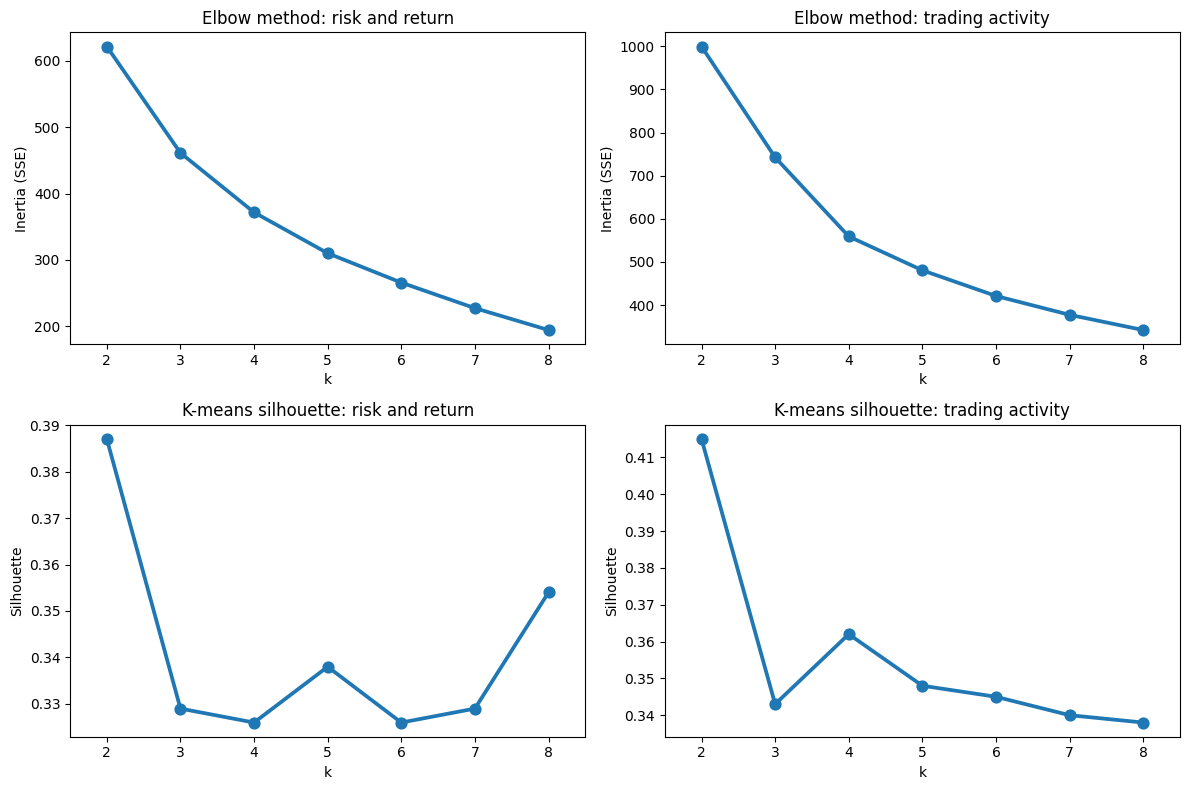

In [26]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.pointplot(x=km_rr_results.index, y=km_rr_results['Inertia'])
plt.title('Elbow method: risk and return'); plt.xlabel('k'); plt.ylabel('Inertia (SSE)')

plt.subplot(2, 2, 2)
sns.pointplot(x=km_rfm_results.index, y=km_rfm_results['Inertia'])
plt.title('Elbow method: trading activity'); plt.xlabel('k'); plt.ylabel('Inertia (SSE)')

plt.subplot(2, 2, 3)
sns.pointplot(x=km_rr_results.index, y=km_rr_results['Silhouette'])
plt.title('K-means silhouette: risk and return'); plt.xlabel('k')

plt.subplot(2, 2, 4)
sns.pointplot(x=km_rfm_results.index, y=km_rfm_results['Silhouette'])
plt.title('K-means silhouette: trading activity'); plt.xlabel('k')

plt.tight_layout()
plt.savefig('kmeans_elbow_silhouette.png', dpi=150)
plt.show()

In [27]:
for k in range(2, 9):
    labels = KMeans(n_clusters=k, random_state=42, n_init=50).fit(X_rr).labels_ + 1
    profile = risk_return.groupby(labels).mean()
    profile['Mean_weekly_return'] = profile['Mean_weekly_return'] * 100
    profile['Count'] = pd.Series(labels).value_counts().sort_index().values
    print('\nRisk/return, k =', k)
    print(profile.round(3))

for k in range(2, 9):
    labels = KMeans(n_clusters=k, random_state=42, n_init=50).fit(X_rfm).labels_ + 1
    profile = activity.groupby(labels).median()
    profile['Monetary'] = profile['Monetary'] / 1e9
    profile['Count'] = pd.Series(labels).value_counts().sort_index().values
    print('\nTrading activity, k =', k)
    print(profile.round(1))


Risk/return, k = 2
   Mean_weekly_return   Beta  Count
1               0.533  1.350    143
2               0.183  0.817    343

Risk/return, k = 3
   Mean_weekly_return   Beta  Count
1               0.596  1.326    119
2               0.259  0.631    202
3               0.095  1.139    165

Risk/return, k = 4
   Mean_weekly_return   Beta  Count
1               0.453  0.979    160
2               0.721  1.700     41
3               0.084  1.203    132
4               0.168  0.576    153

Risk/return, k = 5
   Mean_weekly_return   Beta  Count
1               0.428  0.998    165
2               0.031  0.978    114
3               0.916  1.564     28
4               0.219  0.526    124
5               0.218  1.599     55

Risk/return, k = 6
   Mean_weekly_return   Beta  Count
1               0.225  1.603     56
2               0.962  1.712     20
3               0.264  1.007    134
4              -0.041  0.925     76
5               0.228  0.508    115
6               0.570  1.005     85


In [28]:
K_KM_RR = 5
K_KM_RFM = 4

km_rr = KMeans(n_clusters=K_KM_RR, random_state=42, n_init=50)
km_rr.fit(X_rr)
features['KMeans_RR'] = km_rr.labels_ + 1

km_rfm = KMeans(n_clusters=K_KM_RFM, random_state=42, n_init=50)
km_rfm.fit(X_rfm)
features['KMeans_RFM'] = km_rfm.labels_ + 1

print('K-means risk/return sizes:'); print(features['KMeans_RR'].value_counts().sort_index())
print('\nK-means activity sizes:'); print(features['KMeans_RFM'].value_counts().sort_index())

K-means risk/return sizes:
KMeans_RR
1    165
2    114
3     28
4    124
5     55
Name: count, dtype: int64

K-means activity sizes:
KMeans_RFM
1    120
2    194
3     82
4     90
Name: count, dtype: int64


In [29]:
print('Risk/return: inertia with 50 starts =', round(km_rr.inertia_, 1))
for seed in range(5):
    single = KMeans(n_clusters=K_KM_RR, random_state=seed, n_init=1).fit(X_rr)
    print('  seed', seed, '| one start only, inertia =', round(single.inertia_, 1))

print('\nActivity: inertia with 50 starts =', round(km_rfm.inertia_, 1))
for seed in range(5):
    single = KMeans(n_clusters=K_KM_RFM, random_state=seed, n_init=1).fit(X_rfm)
    print('  seed', seed, '| one start only, inertia =', round(single.inertia_, 1))

Risk/return: inertia with 50 starts = 310.0
  seed 0 | one start only, inertia = 310.3
  seed 1 | one start only, inertia = 320.8
  seed 2 | one start only, inertia = 327.1
  seed 3 | one start only, inertia = 323.0
  seed 4 | one start only, inertia = 313.5

Activity: inertia with 50 starts = 559.2
  seed 0 | one start only, inertia = 559.2
  seed 1 | one start only, inertia = 559.2
  seed 2 | one start only, inertia = 590.4
  seed 3 | one start only, inertia = 559.2
  seed 4 | one start only, inertia = 589.7


2.4 Cluster profiles and algorithm comparison

In [30]:
features['Return_%'] = features['Mean_weekly_return'] * 100
features['Monetary_bn'] = features['Monetary'] / 1e9

print('Ward – risk and return (k=5)')
print(features.groupby('Ward_RR').agg({'Return_%': 'mean', 'Beta': ['mean', 'count']}).round(3))
print('\nK-means – risk and return (k=5)')
print(features.groupby('KMeans_RR').agg({'Return_%': 'mean', 'Beta': ['mean', 'count']}).round(3))

print('\nWard – trading activity (k=3)')
print(features.groupby('Ward_RFM').agg({'Recency': 'median', 'Frequency': 'median', 'Monetary_bn': ['median', 'count']}).round(1))
print('\nK-means – trading activity (k=4)')
print(features.groupby('KMeans_RFM').agg({'Recency': 'median', 'Frequency': 'median', 'Monetary_bn': ['median', 'count']}).round(1))

Ward – risk and return (k=5)
        Return_%   Beta      
            mean   mean count
Ward_RR                      
1          0.132  0.973   182
2          0.632  1.298    92
3          0.422  0.710    98
4          0.200  1.628    48
5          0.088  0.439    66

K-means – risk and return (k=5)
          Return_%   Beta      
              mean   mean count
KMeans_RR                      
1            0.428  0.998   165
2            0.031  0.978   114
3            0.916  1.564    28
4            0.219  0.526   124
5            0.218  1.599    55

Ward – trading activity (k=3)
         Recency Frequency Monetary_bn      
          median    median      median count
Ward_RFM                                    
1           11.0       3.0        11.2   239
2           11.0       3.0        42.0   141
3           46.5       2.0        19.5   106

K-means – trading activity (k=4)
           Recency Frequency Monetary_bn      
            median    median      median count
KMeans_RFM   

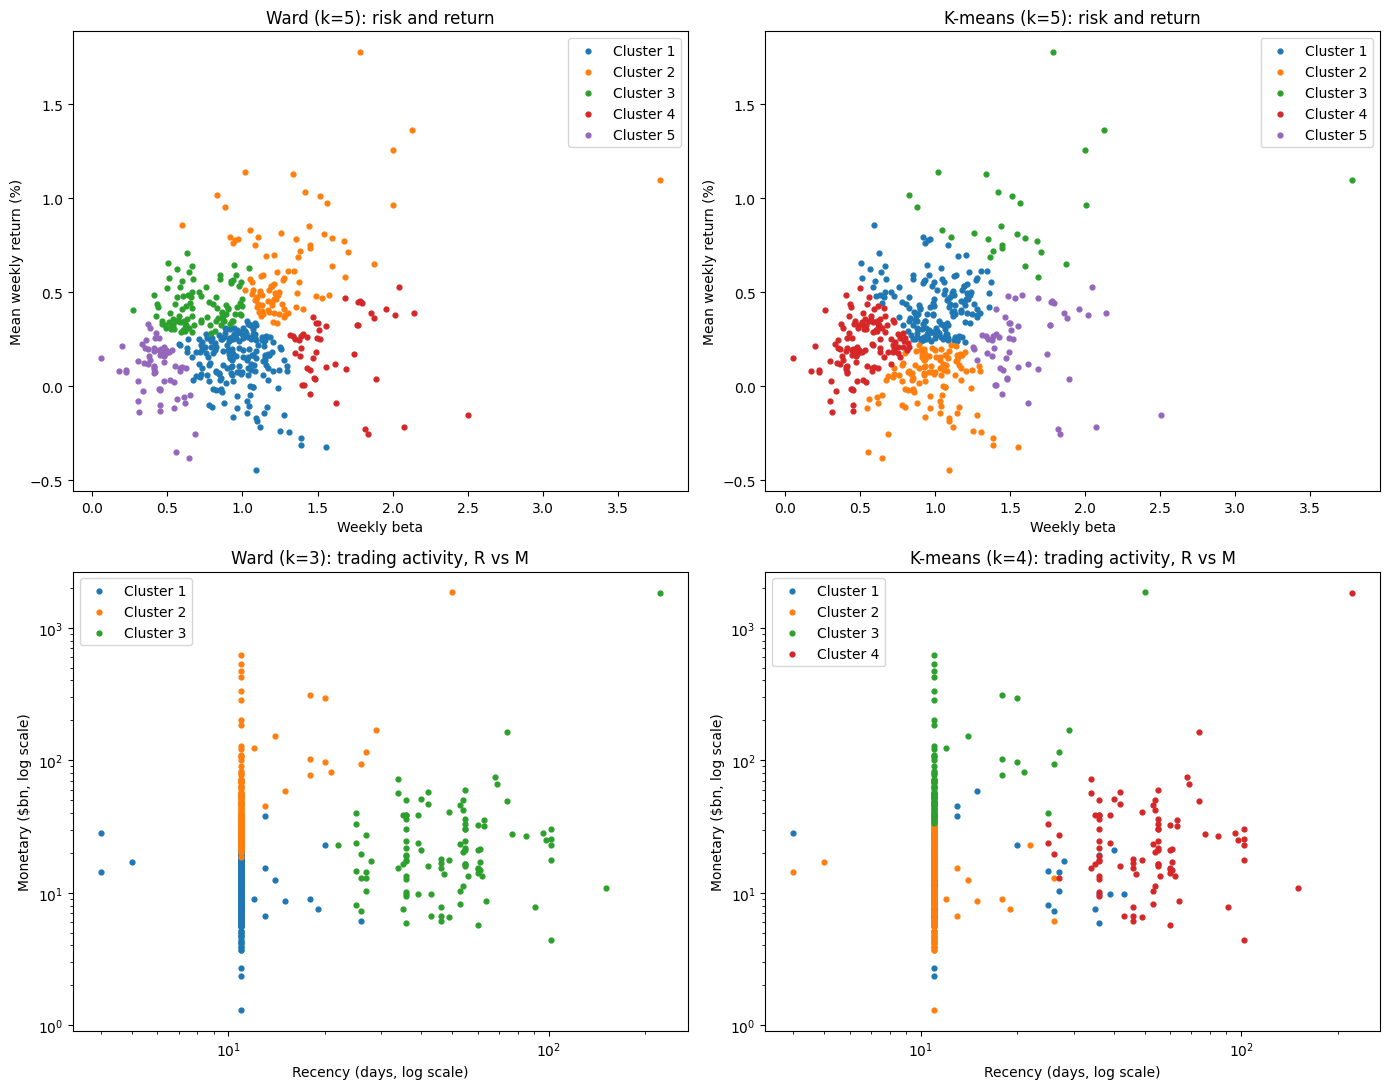

In [31]:
plt.figure(figsize=(14, 11))

plt.subplot(2, 2, 1)
for cluster, group in features.groupby('Ward_RR'):
    plt.scatter(group['Beta'], group['Return_%'], s=12, label='Cluster ' + str(cluster))
plt.title('Ward (k=5): risk and return')
plt.xlabel('Weekly beta'); plt.ylabel('Mean weekly return (%)'); plt.legend()

plt.subplot(2, 2, 2)
for cluster, group in features.groupby('KMeans_RR'):
    plt.scatter(group['Beta'], group['Return_%'], s=12, label='Cluster ' + str(cluster))
plt.title('K-means (k=5): risk and return')
plt.xlabel('Weekly beta'); plt.ylabel('Mean weekly return (%)'); plt.legend()

plt.subplot(2, 2, 3)
for cluster, group in features.groupby('Ward_RFM'):
    plt.scatter(group['Recency'], group['Monetary_bn'], s=12, label='Cluster ' + str(cluster))
plt.xscale('log'); plt.yscale('log')
plt.title('Ward (k=3): trading activity, R vs M')
plt.xlabel('Recency (days, log scale)'); plt.ylabel('Monetary ($bn, log scale)'); plt.legend()

plt.subplot(2, 2, 4)
for cluster, group in features.groupby('KMeans_RFM'):
    plt.scatter(group['Recency'], group['Monetary_bn'], s=12, label='Cluster ' + str(cluster))
plt.xscale('log'); plt.yscale('log')
plt.title('K-means (k=4): trading activity, R vs M')
plt.xlabel('Recency (days, log scale)'); plt.ylabel('Monetary ($bn, log scale)'); plt.legend()

plt.tight_layout()
plt.savefig('cluster_scatter_plots.png', dpi=150)
plt.show()

In [32]:
print('Risk/return: rows = Ward, columns = K-means')
print(pd.crosstab(features['Ward_RR'], features['KMeans_RR']))
print('ARI (1 = identical, 0 = no better than chance):',
      round(adjusted_rand_score(features['Ward_RR'], features['KMeans_RR']), 3))

print('\nTrading activity: rows = Ward, columns = K-means')
print(pd.crosstab(features['Ward_RFM'], features['KMeans_RFM']))
print('ARI:', round(adjusted_rand_score(features['Ward_RFM'], features['KMeans_RFM']), 3))

Risk/return: rows = Ward, columns = K-means
KMeans_RR   1    2   3   4   5
Ward_RR                       
1          49  106   0  24   3
2          60    0  28   0   4
3          56    0   0  42   0
4           0    0   0   0  48
5           0    8   0  58   0
ARI (1 = identical, 0 = no better than chance): 0.329

Trading activity: rows = Ward, columns = K-means
KMeans_RFM   1    2   3   4
Ward_RFM                   
1           93  146   0   0
2           14   46  81   0
3           13    2   1  90
ARI: 0.419


2.5.1 Correlation analysis

In [33]:
rfm_corr = activity_log.corr().round(3)
print(rfm_corr)

           Recency  Frequency  Monetary
Recency      1.000     -0.285     0.127
Frequency   -0.285      1.000     0.013
Monetary     0.127      0.013     1.000


2.5.2 Removal of Monetary

In [34]:
rf_only = activity_log[['Recency', 'Frequency']]

scaler_rf = StandardScaler()
scaler_rf.fit(rf_only)
X_rf = scaler_rf.transform(rf_only)

Z_rf = linkage(X_rf, method='ward', metric='euclidean')
features['Ward_RF_only'] = cut_tree(Z_rf, n_clusters=K_WARD_RFM).ravel() + 1

print('Shares:', len(rf_only), '| k =', K_WARD_RFM)
print(features['Ward_RF_only'].value_counts().sort_index())

Shares: 486 | k = 3
Ward_RF_only
1    125
2    252
3    109
Name: count, dtype: int64


In [35]:
print('Rows = Ward with M (R, F, M), columns = Ward without M (R, F)')
print(pd.crosstab(features['Ward_RFM'], features['Ward_RF_only']))
print('ARI:', round(adjusted_rand_score(features['Ward_RFM'], features['Ward_RF_only']), 3))

Rows = Ward with M (R, F, M), columns = Ward without M (R, F)
Ward_RF_only   1    2    3
Ward_RFM                  
1             66  173    0
2             59   74    8
3              0    5  101
ARI: 0.349


In [36]:
print('WITH M (R, F, M)')
print(features.groupby('Ward_RFM').agg({'Recency': 'median', 'Frequency': 'median', 'Monetary_bn': ['median', 'count']}).round(1))

print('\nWITHOUT M (R, F only)')
print(features.groupby('Ward_RF_only').agg({'Recency': 'median', 'Frequency': 'median', 'Monetary_bn': ['median', 'count']}).round(1))

WITH M (R, F, M)
         Recency Frequency Monetary_bn      
          median    median      median count
Ward_RFM                                    
1           11.0       3.0        11.2   239
2           11.0       3.0        42.0   141
3           46.5       2.0        19.5   106

WITHOUT M (R, F only)
             Recency Frequency Monetary_bn      
              median    median      median count
Ward_RF_only                                    
1               11.0       2.0        17.7   125
2               11.0       4.0        14.7   252
3               46.0       2.0        20.8   109


In [37]:
features.to_csv('feature_table_with_clusters.csv')
print(features[['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM', 'Ward_RF_only']].head())

!zip task2_files.zip *.csv *.png
from google.colab import files
files.download('task2_files.zip')

      Ward_RR  KMeans_RR  Ward_RFM  KMeans_RFM  Ward_RF_only
A           1          2         1           2             1
AAPL        2          1         2           3             1
ABBV        3          4         2           3             2
ABNB        4          5         2           3             2
ABT         5          4         2           2             1
  adding: feature_table.csv (deflated 57%)
  adding: feature_table_with_clusters.csv (deflated 61%)
  adding: cluster_scatter_plots.png (deflated 13%)
  adding: kmeans_elbow_silhouette.png (deflated 12%)
  adding: rfm_before_after_log1p.png (deflated 12%)
  adding: ward_dendrograms.png (deflated 16%)
  adding: ward_silhouette.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>